In [4]:
pip install git+https://github.com/asadullahqb/loan-repayment-challenge.git

  Cloning https://github.com/asadullahqb/loan-repayment-challenge.git to /tmp/pip-req-build-rls5p5oo
  Running command git clone --filter=blob:none --quiet https://github.com/asadullahqb/loan-repayment-challenge.git /tmp/pip-req-build-rls5p5oo
  Resolved https://github.com/asadullahqb/loan-repayment-challenge.git to commit 03c536e9b770ae4504251de965a6984df8b8b202
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for tht: filename=tht-0.1.0-py3-none-any.whl size=3700 sha256=5138e490cfa39bae3cb6f885ad4bc9da3509ebec49a84d5ed662da145e5149dc
  Stored in directory: /tmp/pip-ephem-wheel-cache-_be0n1ss/wheels/49/c7/4b/7c085d00f10ba8e4c7c2705abd377dd5e8afc8ee5d3ee5a2c0
Successfully built tht
  Attempting uninstall: tht
    Found existing installation: tht 0.1.0
    Uninstalling tht-0.1.0:
      Successfully uninstalled tht-0.1.0


In [1]:
# --- Environment bootstrap: make `tht` importable everywhere (no-op locally) ---
import os
import subprocess
import sys
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    REPO = "https://github.com/asadullahqb/loan-repayment-challenge.git"
    REPO_DIR = Path("/content/loan-repayment-challenge")

    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "-q", REPO, str(REPO_DIR)], check=True)

    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO_DIR / "requirements.txt")], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(REPO_DIR)], check=True)

    from google.colab import drive
    drive.mount("/content/drive")
    os.environ["THT_DATA_DIR"] = "/content/drive/MyDrive/tht/data/raw/parquet"

# Fallback: if `tht` isn't importable (e.g. a local kernel that was never
# pip-installed into), add the repo's `src/` directory to sys.path.
try:
    import tht  # noqa: F401
except ModuleNotFoundError as e:
    if e.name != "tht":
        raise
    _found = False
    for _c in (
        Path.cwd() / "src",
        Path.cwd().parent / "src",
        Path.cwd().parent.parent / "src",
        Path("/content/loan-repayment-challenge/src"),
    ):
        if (_c / "tht" / "__init__.py").exists():
            sys.path.insert(0, str(_c))
            _found = True
            break
    if _found:
        import tht  # noqa: F401
        print(f"[bootstrap] added {_c} to sys.path")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[bootstrap] added /content/loan-repayment-challenge/src to sys.path


# Exploratory Data Analysis — Loan Repayment Challenge (Full)

Consolidates all EDA + feasibility analysis performed so far.

Reusable helpers live in the local `tht` package (data loading, EDA, target construction,
evaluation metrics). Import it with `import tht`.

**Join keys:**
- `loan.loanId` <-> `payment.loanId`
- `loan.clarityFraudId` <-> `clarity_underwriting_variables.underwritingid`

**Business context:** short-term, high-cost consumer installment lending (triple-digit APRs).


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tht

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (11, 5)


## 1. Load the data

`tht.load_data()` resolves the raw parquet path from `__file__`, so it works regardless of cwd.


In [3]:
data = tht.load_data()
df_loan = data['loan']
df_payment = data['payment']
df_underwriting = data['underwriting']

for name, df in data.items():
    print(f'{name:<13} {df.shape[0]:>9,} rows x {df.shape[1]:>2} cols')


loan            573,402 rows x 19 cols
payment         689,364 rows x  9 cols
underwriting     49,596 rows x 54 cols


## 2. Missingness overview


In [4]:
for name, df in data.items():
    report = tht.missingness_report(df)
    print(f'\n=== {name}: {len(report)}/{df.shape[1]} columns have nulls ===')
    print(report.head(12).to_string())


=== loan: 10/19 columns have nulls ===
                n_missing  pct_missing
originatedDate     527886        92.06
fpStatus           522233        91.08
clarityFraudId     219989        38.37
apr                  3906         0.68
loanAmount           2234         0.39
payFrequency         1257         0.22
loanStatus            387         0.07
loanId                255         0.04
state                 132         0.02
nPaidOff               24         0.00

=== payment: 2/9 columns have nulls ===
                   n_missing  pct_missing
paymentReturnCode     657831        95.43
paymentStatus         164057        23.80

=== underwriting: 53/54 columns have nulls ===
                                                                                                     n_missing  pct_missing
.underwritingdataclarity.clearfraud.clearfraudidentityverification.phonetype                             48081        96.95
.underwritingdataclarity.clearfraud.clearfraudidentityverification.s

## 3. Loan file — outcome & funnel

`loanStatus` is the key to building the target. Most rows never become loans.


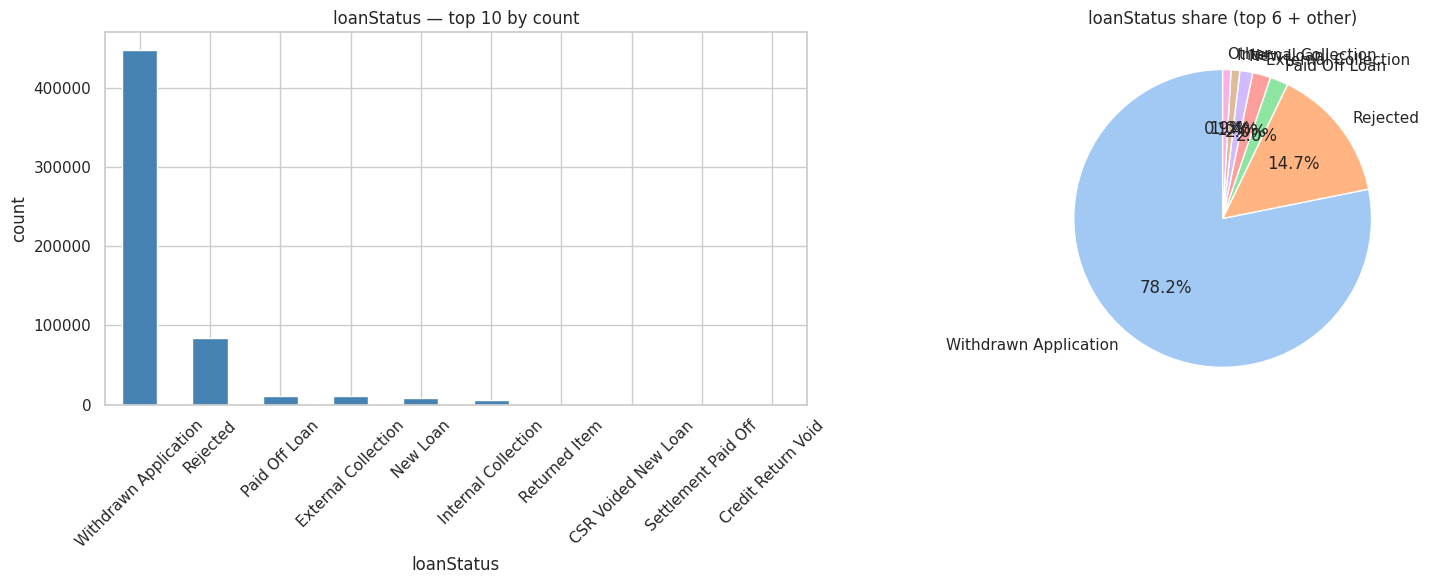

loanStatus
Withdrawn Application       448133
Rejected                     84101
Paid Off Loan                11349
External Collection          11231
New Loan                      7985
Internal Collection           5458
Returned Item                 1173
CSR Voided New Loan           1016
Settlement Paid Off            701
Credit Return Void             695
Customer Voided New Loan       501
NaN                            387
Settled Bankruptcy             325
Pending Paid Off               169
Charged Off Paid Off           160


In [5]:
status = df_loan['loanStatus'].value_counts(dropna=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
status.head(10).plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('loanStatus — top 10 by count')
axes[0].set_ylabel('count')
axes[0].tick_params(axis='x', rotation=45)

top6 = status.head(6).copy()
top6['Other'] = status.iloc[6:].sum()
top6.plot(kind='pie', ax=axes[1], autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
axes[1].set_title('loanStatus share (top 6 + other)')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

print(status.head(15).to_string())


In [6]:
funnel = pd.DataFrame({
    'stage': ['applications', 'originated', 'approved', 'funded'],
    'count': [len(df_loan), df_loan['originated'].sum(), df_loan['approved'].sum(), df_loan['isFunded'].sum()],
})
funnel['pct_of_prev'] = (funnel['count'] / funnel['count'].shift(1) * 100).round(2)
funnel['pct_of_total'] = (funnel['count'] / len(df_loan) * 100).round(2)
funnel


,stage,count,pct_of_prev,pct_of_total
0,applications,573402,NaN,100.00
1,originated,45478,7.93,7.93
2,approved,39591,87.06,6.90
3,funded,38548,97.37,6.72


## 3.1 Numeric features

Note the extreme APRs and ~2x ratio between scheduled repayment and principal.


In [7]:
num_cols = ['apr', 'loanAmount', 'originallyScheduledPaymentAmount', 'nPaidOff', 'leadCost']
df_loan[num_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
apr,"569,496.00",552.97,110.25,0.00,490.00,590.00,601.00,705.59
loanAmount,"571,168.00",513.95,320.48,0.00,350.00,500.00,500.00,"5,000.00"
originallyScheduledPaymentAmount,"573,402.00","1,427.86",923.98,-816.71,"1,022.92","1,245.25","1,615.66","19,963.63"
nPaidOff,"573,378.00",0.04,0.33,0.00,0.00,0.00,0.00,21.00
leadCost,"573,402.00",7.84,12.84,0.00,3.00,3.00,6.00,200.00


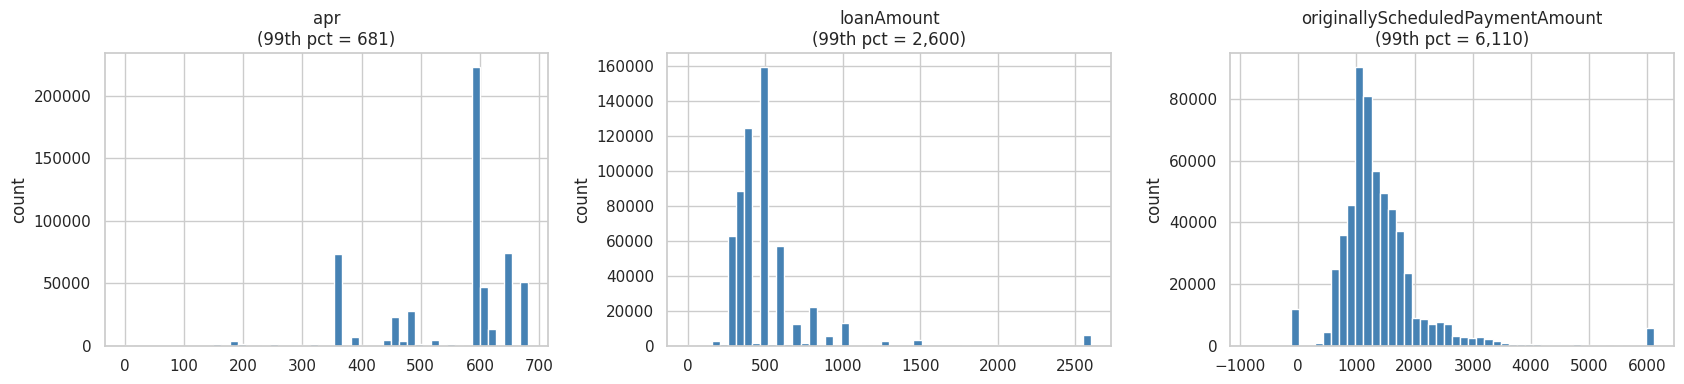

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ['apr', 'loanAmount', 'originallyScheduledPaymentAmount']):
    series = df_loan[col].dropna()
    cap = series.quantile(0.99)
    series.clip(upper=cap).hist(bins=50, ax=ax, color='steelblue')
    ax.set_title(f'{col}\n(99th pct = {cap:,.0f})')
    ax.set_ylabel('count')
plt.tight_layout()
plt.show()


## 3.2 Categorical features


In [9]:
for col in ['payFrequency', 'leadType']:
    print(f'=== {col} ===')
    print(df_loan[col].value_counts(dropna=False).head(12).to_string())
    print()

print('=== state (top 15) ===')
print(df_loan['state'].value_counts(dropna=False).head(15).to_string())


=== payFrequency ===
payFrequency
B      314323
W      136141
M       58784
I       33483
S       29414
NaN      1257

=== leadType ===
leadType
bvMandatory      471932
lead              71690
organic           22679
prescreen          4466
rc_returning       2067
california          474
lionpay              26
repeat               24
express              22
instant-offer        22

=== state (top 15) ===
state
OH    89976
IL    66281
TX    49309
MO    48937
WI    40130
MI    34388
TN    32784
NC    26782
FL    25613
IN    25573
SC    23820
CA    22516
NV    11390
PA     9562
VA     9126


In [10]:
print('nPaidOff — number of prior loans fully repaid (key behavioural feature)')
print(df_loan['nPaidOff'].value_counts(dropna=False).sort_index().head(25).to_string())


nPaidOff — number of prior loans fully repaid (key behavioural feature)
nPaidOff
0.00     560390
1.00       8537
2.00       2596
3.00        915
4.00        427
5.00        211
6.00        132
7.00         56
8.00         25
9.00         15
10.00         9
11.00        16
12.00         8
13.00        10
14.00         8
15.00         1
16.00         1
17.00         2
18.00         6
19.00         7
20.00         5
21.00         1
NaN          24


## 4. Payment file — repayment behaviour

This file is where the **target** and **LGD** signal come from, not application-time features.


In [11]:
print('=== paymentStatus ===')
print(df_payment['paymentStatus'].value_counts(dropna=False).head(12).to_string())
print('\n=== isCollection (custom collection plan) ===')
print(df_payment['isCollection'].value_counts(dropna=False).to_string())
print('\n=== paymentReturnCode (top 15) ===')
print(df_payment['paymentReturnCode'].value_counts(dropna=False).head(15).to_string())


=== paymentStatus ===
paymentStatus
Cancelled                  270334
Checked                    209621
NaN                        164057
Rejected                    32330
Pending                      9241
Skipped                      3761
Rejected Awaiting Retry        18
Complete                        1
Returned                        1

=== isCollection (custom collection plan) ===
isCollection
False    675469
True      13895

=== paymentReturnCode (top 15) ===
paymentReturnCode
NaN       657831
R01        22866
R02         2761
R08         2259
R16         1085
R10          620
MISSED       537
R03          318
RXS          226
R09          176
R07          160
C05          106
C01           87
R20           83
R99           60


In [12]:
n_payments = df_payment.groupby('loanId').size()
print(f'unique loans in payment file: {n_payments.shape[0]:,}')
print('payments per loan:')
print(n_payments.describe().round(1).to_string())


unique loans in payment file: 39,952
payments per loan:
count   39,952.00
mean        17.30
std          7.90
min          3.00
25%         13.00
50%         13.00
75%         24.00
max        105.00


Example amortization — loan LL-I-00000021: 13 installments


,loanId,installmentIndex,isCollection,paymentDate,principal,fees,paymentAmount,paymentStatus,paymentReturnCode
0,LL-I-00000021,1,False,2014-12-19T05:00:00,22.33,147.28,169.61,Checked,NaN
12,LL-I-00000021,1,True,2016-04-28T22:44:43.736000,0.01,0.00,0.01,Checked,NaN
1,LL-I-00000021,2,False,2015-01-02T05:00:00,26.44,143.17,169.61,Checked,NaN
2,LL-I-00000021,3,False,2015-01-16T05:00:00,31.30,138.31,169.61,Checked,NaN
3,LL-I-00000021,4,False,2015-01-30T05:00:00,37.07,132.54,169.61,Checked,NaN
4,LL-I-00000021,5,False,2015-02-13T05:00:00,43.89,125.72,169.61,Checked,NaN
5,LL-I-00000021,6,False,2015-02-27T05:00:00,51.97,117.64,169.61,Checked,NaN
6,LL-I-00000021,7,False,2015-03-13T04:00:00,61.54,108.07,169.61,Checked,NaN


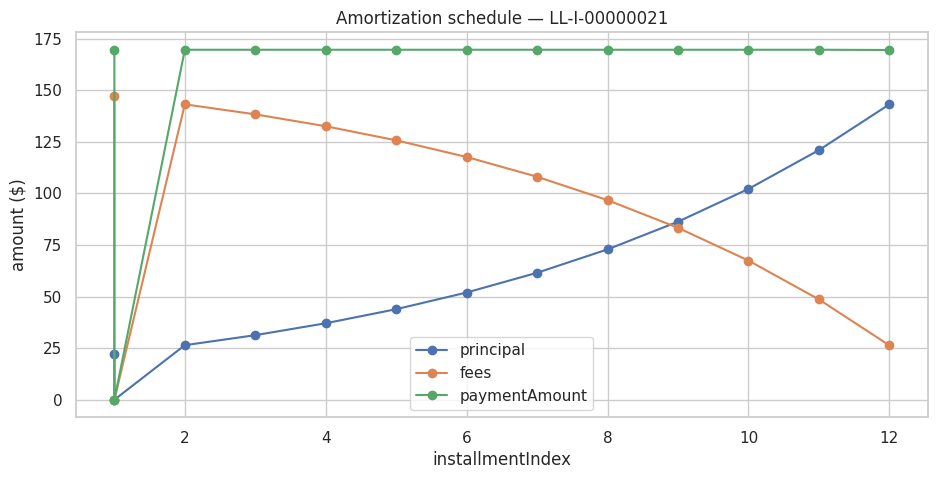

In [13]:
example_loan = df_payment['loanId'].iloc[0]
ex = df_payment[df_payment['loanId'] == example_loan].sort_values('installmentIndex')
print(f'Example amortization — loan {example_loan}: {len(ex)} installments')
display(ex.head(8))

ex.plot(x='installmentIndex', y=['principal', 'fees', 'paymentAmount'], marker='o', figsize=(11, 5))
plt.title(f'Amortization schedule — {example_loan}')
plt.ylabel('amount ($)')
plt.xlabel('installmentIndex')
plt.show()


## 5. Underwriting file — fraud / identity (third-party Clarity data)

**Coverage nuance:** clarity data covers only ~9% of *all* applications, but **~83% of resolved (funded) loans**.


In [14]:
n_with_cf = df_loan['clarityFraudId'].notna().sum()
print(f'loans with clarityFraudId:  {n_with_cf:,} ({n_with_cf/len(df_loan)*100:.1f}%) of ALL applications')
print(f'underwriting report rows:    {len(df_underwriting):,}')
print(f'unique underwriting ids:     {df_underwriting["underwritingid"].nunique():,}')
print()
print('clearFraudScore (higher = lower default risk):')
print(df_underwriting['clearfraudscore'].describe().to_string())


loans with clarityFraudId:  353,413 (61.6%) of ALL applications
underwriting report rows:    49,596
unique underwriting ids:     49,596

clearFraudScore (higher = lower default risk):
count   49,459.00
mean       683.72
std        126.25
min        122.00
25%        592.00
50%        691.00
75%        783.00
max        965.00


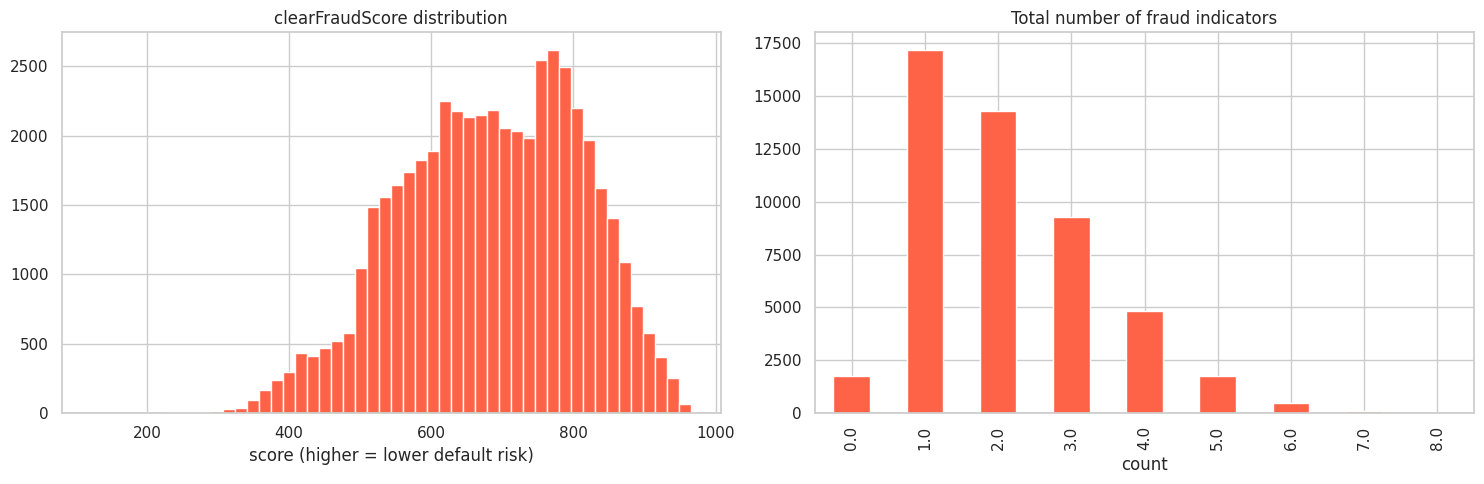

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
df_underwriting['clearfraudscore'].hist(bins=50, ax=axes[0], color='tomato')
axes[0].set_title('clearFraudScore distribution')
axes[0].set_xlabel('score (higher = lower default risk)')

total_col = [c for c in df_underwriting.columns if 'totalnumberoffraudindicators' in c]
if total_col:
    df_underwriting[total_col[0]].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='tomato')
    axes[1].set_title('Total number of fraud indicators')
    axes[1].set_xlabel('count')
plt.tight_layout()
plt.show()


In [16]:
sparsity = tht.fraud_indicator_sparsity(df_underwriting)
print(f'{len(sparsity)} fraud-indicator columns. Positive (True) rate:')
print(sparsity.to_string())
print()
print(f'mean positive rate across indicators: {sparsity.mean():.4f}')
print('(near-constant indicators, e.g. ~0 or ~1, carry little signal and should be dropped)')


29 fraud-indicator columns. Positive (True) rate:
.underwritingdataclarity.clearfraud.clearfraudindicator.telephonenumberinconsistentwithaddress      0.92
.underwritingdataclarity.clearfraud.clearfraudindicator.inquiryonfilecurrentaddressconflict         0.25
.underwritingdataclarity.clearfraud.clearfraudindicator.inquiryaddressnonresidential                0.15
.underwritingdataclarity.clearfraud.clearfraudindicator.driverlicenseformatinvalid                  0.12
.underwritingdataclarity.clearfraud.clearfraudindicator.inquirycurrentaddressnotonfile              0.11
.underwritingdataclarity.clearfraud.clearfraudindicator.telephonenumberinconsistentwithstate        0.08
.underwritingdataclarity.clearfraud.clearfraudindicator.currentaddressreportedbynewtradeonly        0.07
.underwritingdataclarity.clearfraud.clearfraudindicator.onfileaddressnonresidential                 0.07
.underwritingdataclarity.clearfraud.clearfraudindicator.workphonepreviouslylistedascellphone        0.07
.unde

## 6. Target construction

`tht.build_target()` applies the preliminary default label. Refined later with payment return codes.


In [17]:
outcome = tht.build_target(df_loan)

print(f'Loans with definitive repayment outcome: {len(outcome):,} of {len(df_loan):,} total')
print(f"  Good (Paid Off):      {(outcome['defaulted']==0).sum():,}")
print(f"  Bad  (defaulted):     {(outcome['defaulted']==1).sum():,}")
print(f"  Default rate:         {outcome['defaulted'].mean()*100:.1f}%")


Loans with definitive repayment outcome: 28,524 of 573,402 total
  Good (Paid Off):      11,349
  Bad  (defaulted):     17,175
  Default rate:         60.2%


## 6.1 Default rate by segment — the strongest application-time signals


In [18]:
tht.segment_default_rate(outcome, 'leadType')


,n,default_rate
leadType,,
bvMandatory,13533,0.68
lead,7066,0.64
prescreen,1062,0.54
california,37,0.43
organic,5919,0.43
repeat,9,0.33
rc_returning,877,0.30
express,10,0.10
lionpay,10,0.00


In [19]:
outcome = outcome.assign(
    npo=pd.cut(outcome['nPaidOff'], [-1, 0, 1, 5, 1000], labels=['0', '1', '2-5', '6+'])
)
tht.segment_default_rate(outcome, 'npo')


,n,default_rate
npo,,
0,22743,0.66
1,3751,0.41
2-5,1842,0.30
6+,169,0.10


## 6.2 Predictive power of the fraud score (single feature)

A quick AUC of `clearfraudscore` against the default label, on the resolved-and-covered subset.


In [20]:
u = outcome[outcome['hasCF'] == 1].merge(
    df_underwriting[['underwritingid', 'clearfraudscore']],
    left_on='clarityFraudId', right_on='underwritingid', how='inner',
).dropna(subset=['clearfraudscore', 'defaulted'])

print(f'resolved & hasCF rows: {len(u):,} | default rate: {u["defaulted"].mean():.3f}')
print(f'coverage among resolved: {(outcome["hasCF"]==1).mean()*100:.1f}%')
print(f'AUC(clearfraudscore -> default): {tht.auc(u["defaulted"], u["clearfraudscore"]):.3f}')


resolved & hasCF rows: 23,561 | default rate: 0.619
coverage among resolved: 83.1%
AUC(clearfraudscore -> default): 0.634


## 7. Key findings

1. **Most applications never become loans** — ~78% `Withdrawn Application`, ~15% `Rejected`; only ~7% originate.
2. **High-cost, short-term lending** — APRs of 360-590% and scheduled repayment ~ 2x principal.
3. **Resolved cohort is small but adequate** — 28,524 loans with a definitive outcome, 60.2% default rate.
4. **`nPaidOff` is monotonic and strong** — 0 -> 66% default, 1 -> 41%, 2-5 -> 30%, 6+ -> 9.5%.
5. **`leadType` separates strongly** — `bvMandatory` 68% default vs `express` 10%.
6. **Fraud data is well-covered where it matters** — only 9% of all applications, but 83% of resolved loans.
7. **`clearfraudscore` is a strong single feature** — AUC 0.634 against default on its own.
8. **Fraud indicators are sparse** (mean 6.9% positive); one near-constant (92% true) should be dropped.

### Feasibility vs a 70% (AUC) bar
- **PD:** supported — full feature set should clear AUC >= 0.70.
- **Fraud model:** not measurable — no ground-truth fraud label.
- **LGD:** under-powered — ~17k defaults, noisy target; 70% R^2 unrealistic.
- **EAD / eligibility:** N/A — fixed-term loans / deterministic rules, not ML.
